In [1]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:


path = "/dataset.csv" if os.path.exists("/dataset.csv") else "dataset.csv"
df = pd.read_csv(path)
print(df.shape)

(20000, 2)


In [3]:
print(df.shape)
print(df["label"].value_counts())
df.head()

(20000, 2)
label
1    10000
0    10000
Name: count, dtype: int64


,url,label
0,mulheresdejoelhos.com.br/wp-includes/pomo/nat/...,1
1,paypams.com,0
2,blessthismessplease.com,0
3,transparent.com/polish/,0
4,gfvds.uytbyvr.club/,1


In [4]:
df = pd.read_csv("/dataset.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(20000, 2)
['url', 'label']


,url,label
0,mulheresdejoelhos.com.br/wp-includes/pomo/nat/...,1
1,paypams.com,0
2,blessthismessplease.com,0
3,transparent.com/polish/,0
4,gfvds.uytbyvr.club/,1


In [5]:
print(df.iloc[:, -1].value_counts())
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

label
1    10000
0    10000
Name: count, dtype: int64
0 missing values
0 duplicate rows


In [6]:
print(df.shape)
print(df.dtypes)

(20000, 2)
url      object
label     int64
dtype: object


In [7]:
def extract_features(url):
    url = str(url)
    full = url if "://" in url else "http://" + url
    try:
        p = urlparse(full)
        host, path = p.netloc, p.path
    except ValueError:
        host, path = "", ""
    host = host.split(":")[0]

    return {
        "url_length": len(url),
        "host_length": len(host),
        "path_length": len(path),
        "num_dots": url.count("."),
        "num_hyphens": url.count("-"),
        "num_digits": sum(c.isdigit() for c in url),
        "num_slashes": url.count("/"),
        "num_params": url.count("?") + url.count("&"),
        "has_at": int("@" in url),
        "has_ip": int(bool(re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host))),
        "num_subdomains": max(host.count(".") - 1, 0),
        "is_https": int(url.lower().startswith("https")),
        "has_susp_word": int(any(w in url.lower() for w in
            ["login", "verify", "secure", "account", "update", "bank", "confirm"])),
    }

In [8]:
X = df["url"].apply(extract_features).apply(pd.Series)
y = df["label"]

print(X.shape)
X.head()

(20000, 13)


,url_length,host_length,path_length,num_dots,num_hyphens,num_digits,num_slashes,num_params,has_at,has_ip,num_subdomains,is_https,has_susp_word
0,60,24,36,3,1,1,5,0,0,0,1,0,1
1,11,11,0,1,0,0,0,0,0,0,0,0,0
2,23,23,0,1,0,0,0,0,0,0,0,0,0
3,23,15,8,1,0,0,2,0,0,0,0,0,0
4,19,18,1,2,0,0,1,0,0,0,1,0,0


In [9]:
X.head().T

,0,1,2,3,4
url_length,60,11,23,23,19
host_length,24,11,23,15,18
path_length,36,0,0,8,1
num_dots,3,1,1,1,2
num_hyphens,1,0,0,0,0
num_digits,1,0,0,0,0
num_slashes,5,0,0,2,1
num_params,0,0,0,0,0
has_at,0,0,0,0,0
has_ip,0,0,0,0,0


In [10]:
print(X["is_https"].value_counts())
print("has_ip:", X["has_ip"].sum(), "| has_at:", X["has_at"].sum())

is_https
0    19999
1        1
Name: count, dtype: int64
has_ip: 218 | has_at: 155


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (16000, 13)
Test: (4000, 13)


In [12]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["legit (0)", "phishing (1)"]))

Accuracy: 0.8445
              precision    recall  f1-score   support

   legit (0)       0.83      0.87      0.85      2000
phishing (1)       0.86      0.82      0.84      2000

    accuracy                           0.84      4000
   macro avg       0.85      0.84      0.84      4000
weighted avg       0.85      0.84      0.84      4000



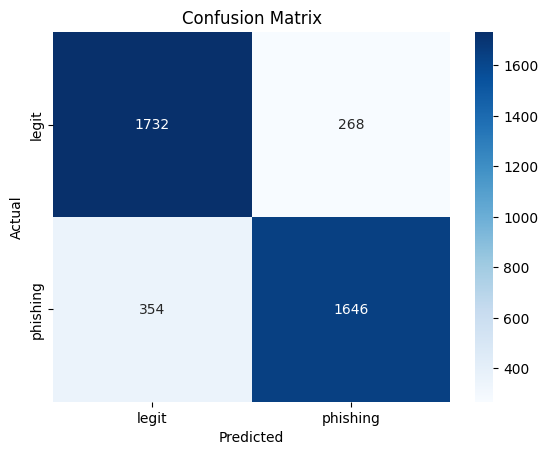

In [13]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["legit", "phishing"], yticklabels=["legit", "phishing"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

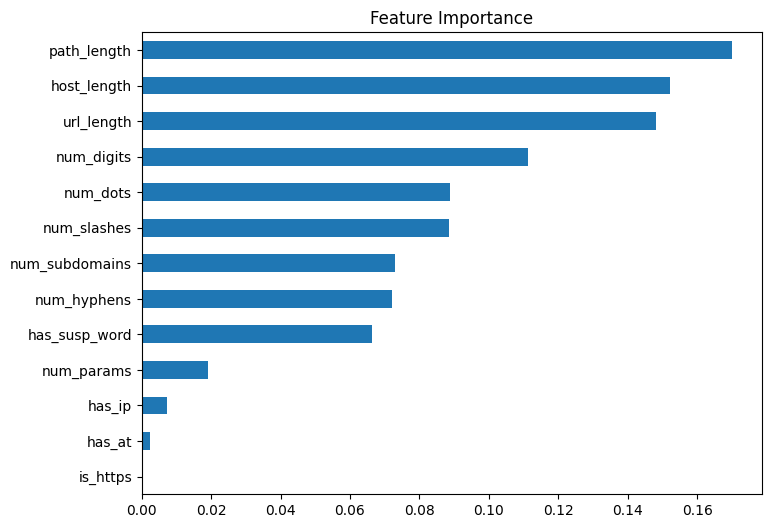

In [14]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 6), title="Feature Importance")
plt.show()

In [15]:
!pip freeze | grep -E "^(pandas|numpy|scikit-learn|matplotlib|seaborn)=="

matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
seaborn==0.13.2
